# Viviendas de grandes tenedores privados por comunidad autónoma

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "viviendas-grandes-tenedores"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Viviendas de grandes tenedores privados por comunidad autónoma"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "por_ccaa"  # serie_temporal | por_ccaa | solo_espana
VISTA = "ultimo_anio"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = 100  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de las viviendas"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué parte de las viviendas pertenece a «grandes tenedores» privados: personas físicas o jurídicas privadas que son titulares de más de 10 viviendas, el umbral de la Ley 12/2023, por el derecho a la vivienda. Datos de la Dirección General del Catastro.

**Cómo se lee.** Un valor de 3 significa que el 3 % de las viviendas de la comunidad tiene como titular a un gran tenedor privado. La línea gruesa es el total y las grises, las comunidades.

**Limitaciones.**
- El titular es quien figura como contribuyente del IBI, que no siempre coincide con el propietario.
- El Catastro no identifica fondos de inversión: cuenta personas físicas y jurídicas privadas por número de viviendas.
- Navarra y País Vasco tienen catastro propio y no aparecen; el total es el del territorio de régimen común.
- Solo hay datos desde 2024.

## 2. Descarga

Dirección General del Catastro, estadísticas de titularidad: padrones `P_SPI_total_V` y `P_SPI_aut_V` (inmuebles urbanos de uso residencial). Se descargan los inmuebles de titulares privados con más de 10 viviendas (tramos de 11 a 25, de 26 a 100 y más de 100; personas físicas `PF` y jurídicas privadas `PJ`) y el total de inmuebles.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import catastro

TRAMOS = [f"I_U_{t}_{g}" for t in ("PF", "PJ") for g in ("HASTA_25", "HASTA_100", "MAYOR_100")]
ANIOS = range(2024, date.today().year + 1)  # los padrones con tramos empiezan en 2024


def descargar():
    grandes, fuentes = catastro.get(TRAMOS, anios=ANIOS, omitir_ausentes=True)
    total, _ = catastro.get("INMUEBLES", anios=ANIOS, omitir_ausentes=True)
    return grandes, total, fuentes


grandes, total, fuentes_descarga = descargar()

## 3. Transformación

Porcentaje = viviendas de grandes tenedores privados / total de viviendas × 100, por comunidad y año.

In [ ]:
from lib.tipos import FuenteMeta

clave = ["serie", "periodo"]
df = grandes.merge(total, on=clave, suffixes=("_grandes", "_total"))
df = df.assign(valor=df["valor_grandes"] / df["valor_total"] * 100)[["serie", "periodo", "valor"]]
CODIGO = "Titularidad catastral, P_SPI_<nivel>_V (I_U_PF y I_U_PJ con más de 10 inmuebles / INMUEBLES)"
fuentes = [FuenteMeta(f.serie, f.organismo, CODIGO, f.url, f.fecha_consulta) for f in fuentes_descarga]

NOTAS = [
    "Dirección General del Catastro, estadísticas de titularidad: inmuebles urbanos de uso residencial cuyo titular (contribuyente del IBI) es una persona física o jurídica privada con más de 10 de esos inmuebles, en porcentaje del total de inmuebles urbanos de uso residencial.",
    "Más de 10 viviendas es el umbral de gran tenedor de la Ley 12/2023. El Catastro no identifica fondos de inversión. No se cuentan las entidades públicas ni los titulares sin personalidad jurídica definida.",
    "Navarra y País Vasco tienen catastro propio y no aparecen; la serie España es el territorio de régimen común.",
    "Los padrones con tramos por número de inmuebles se publican desde 2024 (situación a primeros de octubre de cada año).",
]

## 4. Visualización

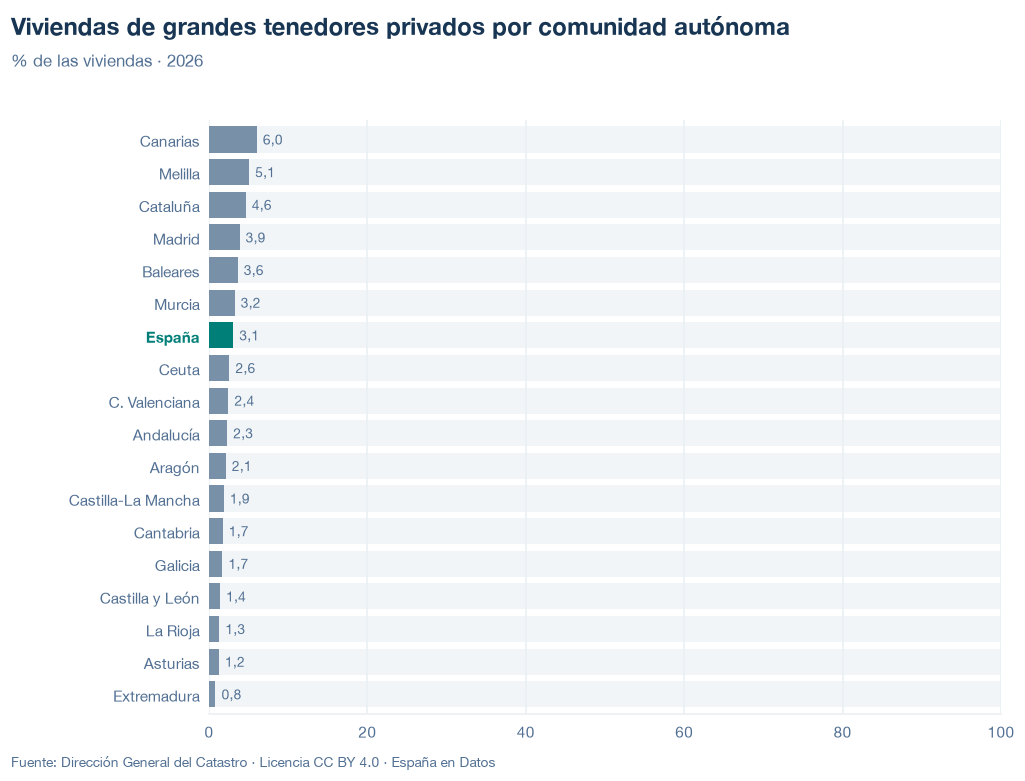

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/viviendas-grandes-tenedores.json y data/viviendas-grandes-tenedores.csv


## 6. Fuentes, notas y licencia

- Dirección General del Catastro, estadísticas de titularidad (`P_SPI_total_V`, `P_SPI_aut_V`).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.